#random forest

In [1]:
from google.colab import files
import pandas as pd
uploaded = files.upload()
df = pd.read_csv("PhishFOE_ds.csv", header=0)

Saving PhishFOE_ds.csv to PhishFOE_ds.csv


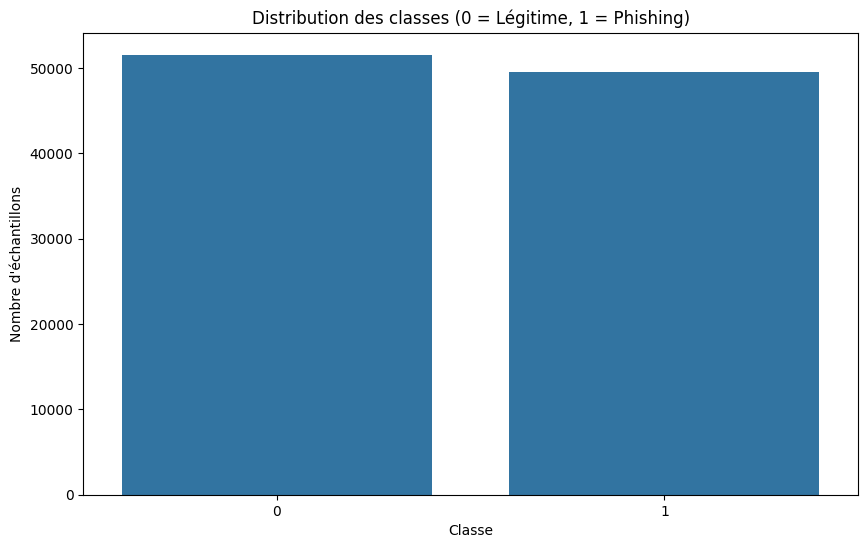

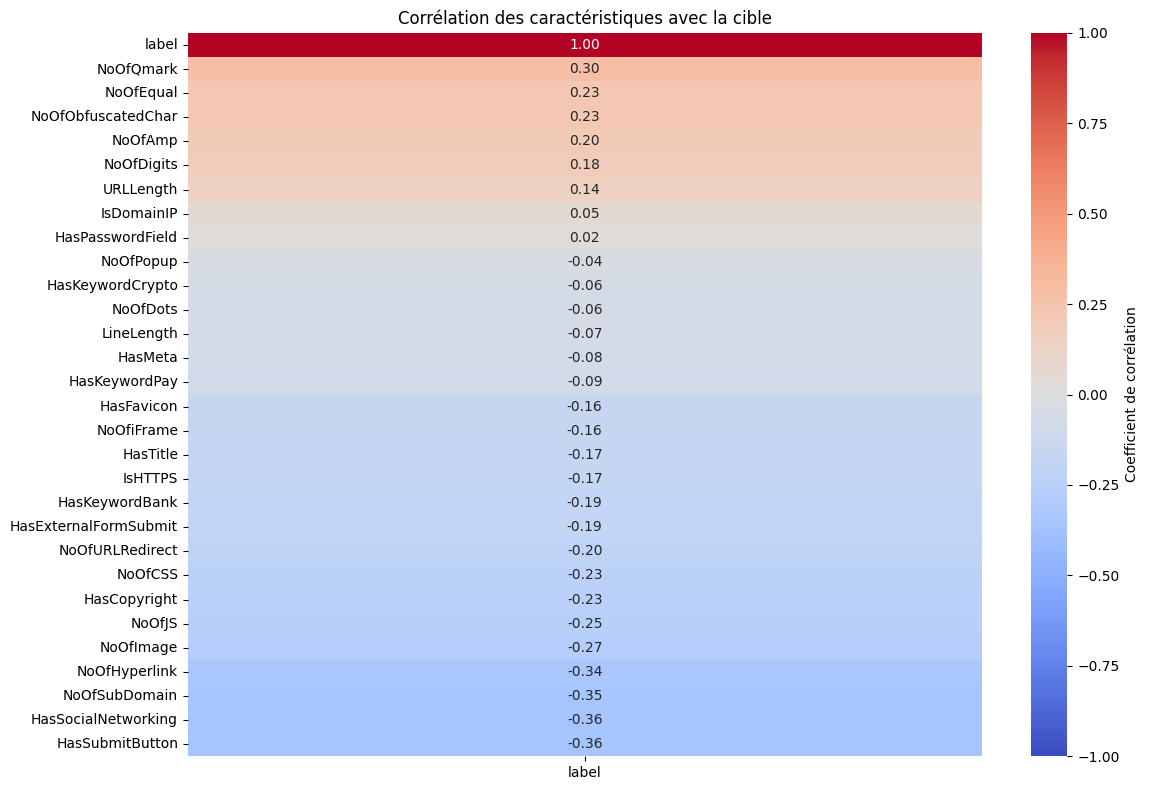

Classes équilibrées - SMOTE non appliqué.
Classification Report :
               precision    recall  f1-score   support

           0       0.99      0.99      0.99     10349
           1       0.99      0.99      0.99      9662

    accuracy                           0.99     20011
   macro avg       0.99      0.99      0.99     20011
weighted avg       0.99      0.99      0.99     20011



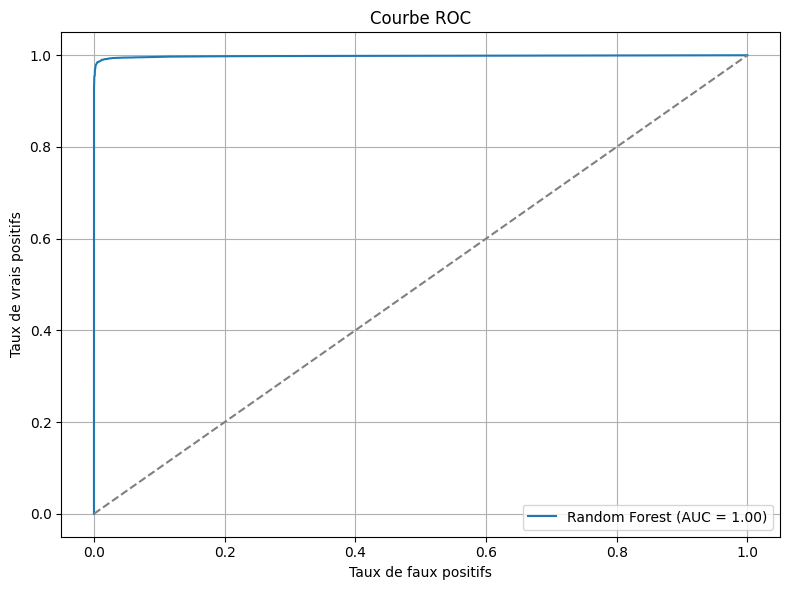

Validation Accuracy: 0.9896


In [9]:
# ---------------------------------------------------
# Import necessary libraries
# ---------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from imblearn.over_sampling import SMOTE

# ---------------------------------------------------
# 1. Prepare data
# ---------------------------------------------------
target_col = 'label'

# EDA - Distribution des classes
plt.figure(figsize=(10, 6))
sns.countplot(x=target_col, data=df)
plt.title('Distribution des classes (0 = Légitime, 1 = Phishing)')
plt.xlabel('Classe')
plt.ylabel("Nombre d'échantillons")
plt.show()

# Heatmap de corrélation
plt.figure(figsize=(12, 8))
correlation = df.corr(numeric_only=True)
sns.heatmap(correlation[[target_col]].sort_values(by=target_col, ascending=False),
            annot=True, cmap='coolwarm', vmin=-1, vmax=1,
            fmt='.2f', cbar_kws={'label': 'Coefficient de corrélation'})
plt.title('Corrélation des caractéristiques avec la cible')
plt.tight_layout()
plt.show()
df = df.select_dtypes(include=[np.number, 'int64', 'float64'])
# Features / Target split
X = df.drop(columns=['label']).values
y = df['label'].astype(int).values

# ---------------------------------------------------
# 2. Feature normalization
# ---------------------------------------------------
scaler = StandardScaler()
X = scaler.fit_transform(X)

# ---------------------------------------------------
# 3. Anomaly detection with IsolationForest
# ---------------------------------------------------
chosen_contamination = 0.01
iso = IsolationForest(contamination=chosen_contamination, random_state=42)
mask = iso.fit_predict(X) != -1
X, y = X[mask], y[mask]

# ---------------------------------------------------
# 4. Class balancing with SMOTE
# ---------------------------------------------------
if np.bincount(y).min() < np.bincount(y).max() * 0.5:
    smote = SMOTE(random_state=42)
    X, y = smote.fit_resample(X, y)
    print("Distribution après SMOTE:", np.bincount(y))
else:
    print("Classes équilibrées - SMOTE non appliqué.")

# ---------------------------------------------------
# 5. Model training (example: RandomForest)
# ---------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# ---------------------------------------------------
# 6. Evaluation
# ---------------------------------------------------
print("Classification Report :\n", classification_report(y_test, y_pred))

# ROC Curve
y_proba = model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Random Forest (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("Taux de faux positifs")
plt.ylabel("Taux de vrais positifs")
plt.title("Courbe ROC")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
accuracy = (y_pred == y_test).mean()
print(f"Validation Accuracy: {accuracy:.4f}")

#adaboost

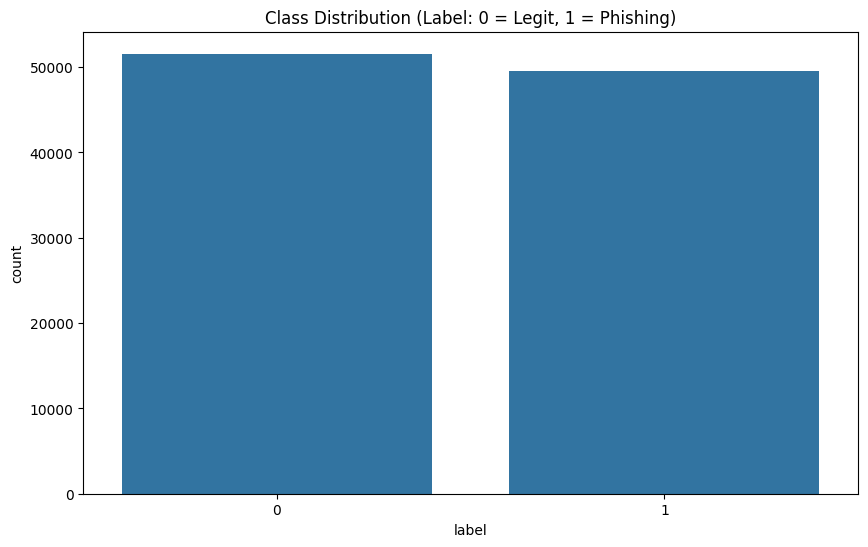

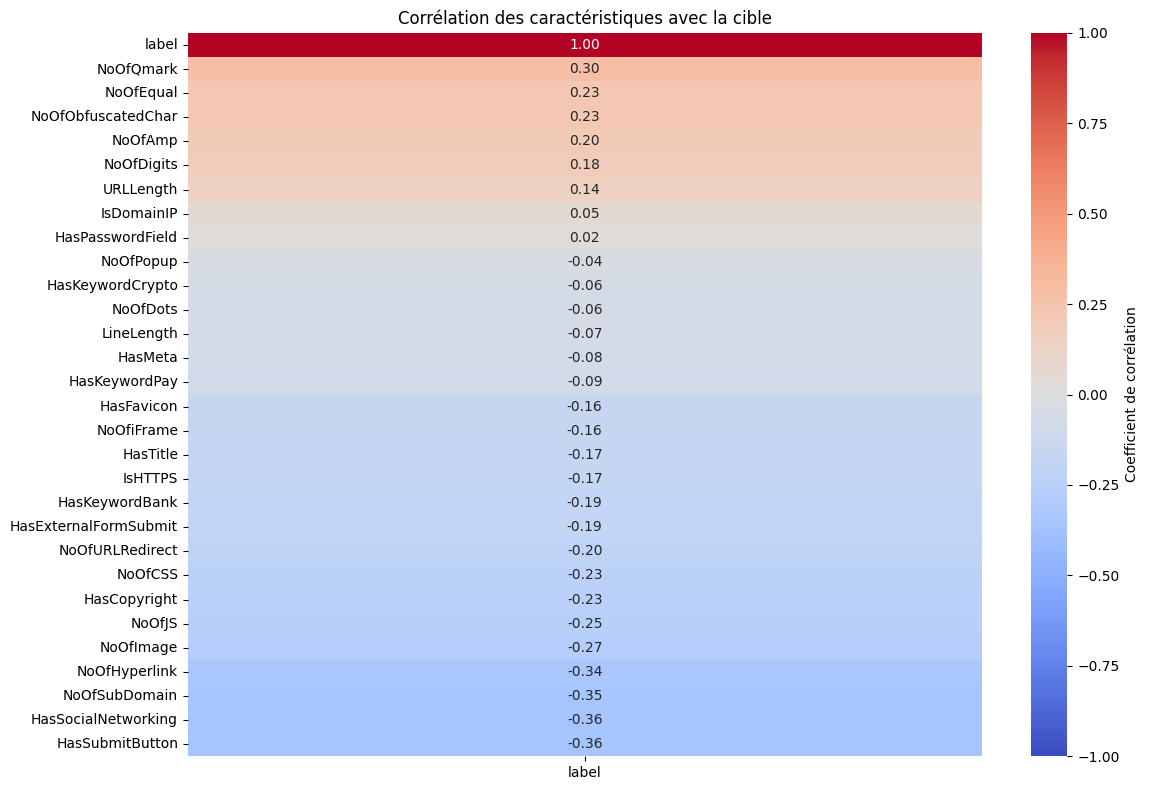

Contamination 0.005: Removed 504 points
Contamination 0.01: Removed 1011 points
Contamination 0.02: Removed 2022 points
Classes are balanced. SMOTE skipped.
AdaBoost training complete.

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.94      0.97      0.96     10275
           1       0.97      0.94      0.95      9736

    accuracy                           0.96     20011
   macro avg       0.96      0.95      0.95     20011
weighted avg       0.96      0.96      0.96     20011



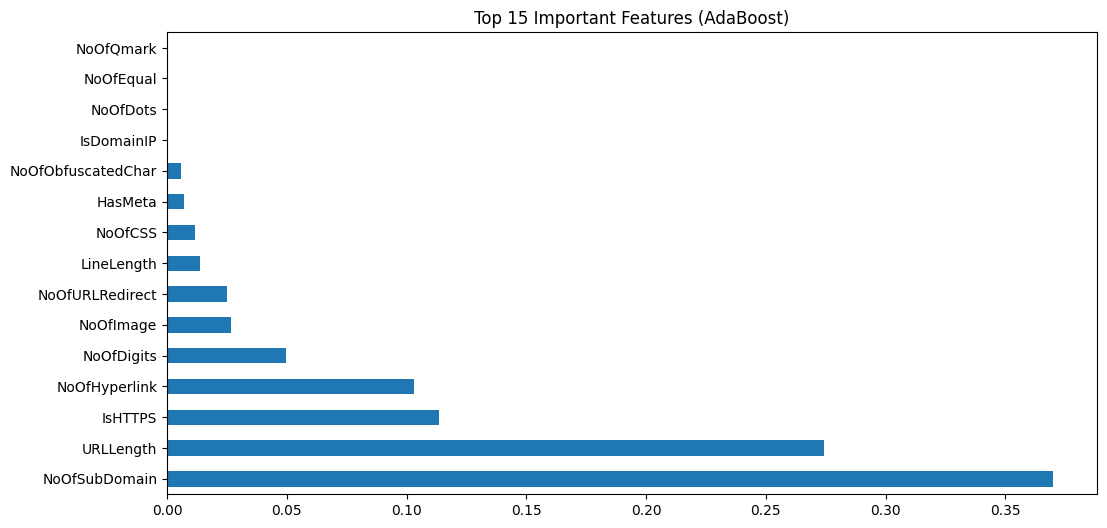

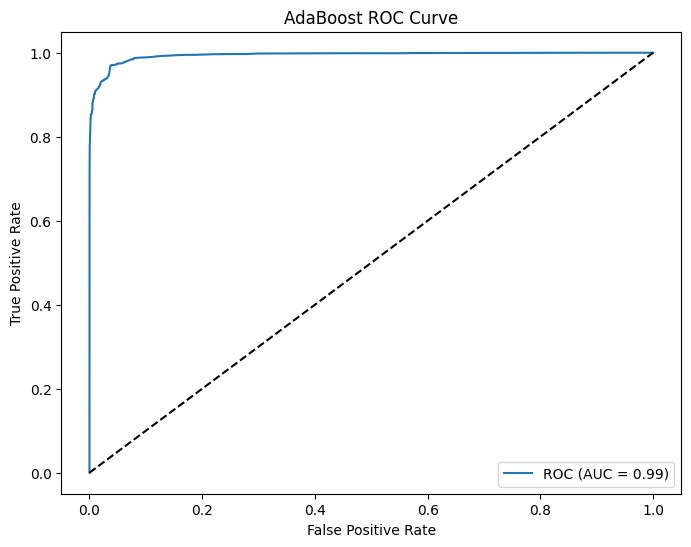

Validation Accuracy: 0.9551


In [10]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and model evaluation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

# Models and sampling
from sklearn.ensemble import AdaBoostClassifier, IsolationForest
from sklearn.tree import DecisionTreeClassifier
from imblearn.over_sampling import SMOTE

# ---------------------------
# 1. Prepare data
# ---------------------------

# Exploratory visualization
plt.figure(figsize=(10, 6))
sns.countplot(x='label', data=df)
plt.title('Class Distribution (Label: 0 = Legit, 1 = Phishing)')
plt.show()

plt.figure(figsize=(12, 8))
correlation = df.corr(numeric_only=True)
sns.heatmap(correlation[[target_col]].sort_values(by=target_col, ascending=False),
            annot=True, cmap='coolwarm', vmin=-1, vmax=1,
            fmt='.2f', cbar_kws={'label': 'Coefficient de corrélation'})
plt.title('Corrélation des caractéristiques avec la cible')
plt.tight_layout()
plt.show()

# Separate features and target
df = df.select_dtypes(include=[np.number, 'int64', 'float64'])
# Features / Target split
X = df.drop(columns=['label']).values
y = df['label'].astype(int).values

# ---------------------------
# 2. Feature normalization
# ---------------------------
scaler = StandardScaler()
X = scaler.fit_transform(X)

# ---------------------------
# 3. Anomaly detection with IsolationForest
# ---------------------------
# Test different contamination levels
for contamination in [0.005, 0.01, 0.02]:
    iso = IsolationForest(contamination=contamination, random_state=42)
    pred_anomalies = iso.fit_predict(X)
    mask = pred_anomalies != -1
    removed_points = len(X) - np.sum(mask)
    print(f"Contamination {contamination}: Removed {removed_points} points")

# Choose contamination level
chosen_contamination = 0.01
iso = IsolationForest(contamination=chosen_contamination, random_state=42)
pred_anomalies = iso.fit_predict(X)
mask = pred_anomalies != -1
X = X[mask]
y = y[mask]

# ---------------------------
# 4. Class balancing with SMOTE
# ---------------------------
if np.bincount(y).min() < np.bincount(y).max() * 0.5:  # Check imbalance
    smote = SMOTE(random_state=42)
    X, y = smote.fit_resample(X, y)
    print("Class distribution after SMOTE:", np.bincount(y))
else:
    print("Classes are balanced. SMOTE skipped.")

# ---------------------------
# 5. Train/test split
# ---------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                  test_size=0.2,
                                                  random_state=42,
                                                  stratify=y)

# ---------------------------
# 6. AdaBoost model training
# ---------------------------
base_estimator = DecisionTreeClassifier(max_depth=1, random_state=42)  # Decision stump
ada_model = AdaBoostClassifier(estimator=base_estimator,
                             n_estimators=200,       # Increased number of estimators
                             learning_rate=0.5,      # Lower learning rate
                             random_state=42)

ada_model.fit(X_train, y_train)
print("AdaBoost training complete.")

# ---------------------------
# 7. Model evaluation
# ---------------------------
y_pred = ada_model.predict(X_test)
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred))

# Feature importance
plt.figure(figsize=(12, 6))
feat_importances = pd.Series(
    ada_model.feature_importances_,
    index=df.drop(columns=['label']).columns
)
feat_importances.nlargest(15).plot(kind='barh')
plt.title('Top 15 Important Features (AdaBoost)')
plt.show()

# ROC Curve
y_proba = ada_model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('AdaBoost ROC Curve')
plt.legend()
plt.show()

accuracy = (y_pred == y_test).mean()
print(f"Validation Accuracy: {accuracy:.4f}")

#lightgbm

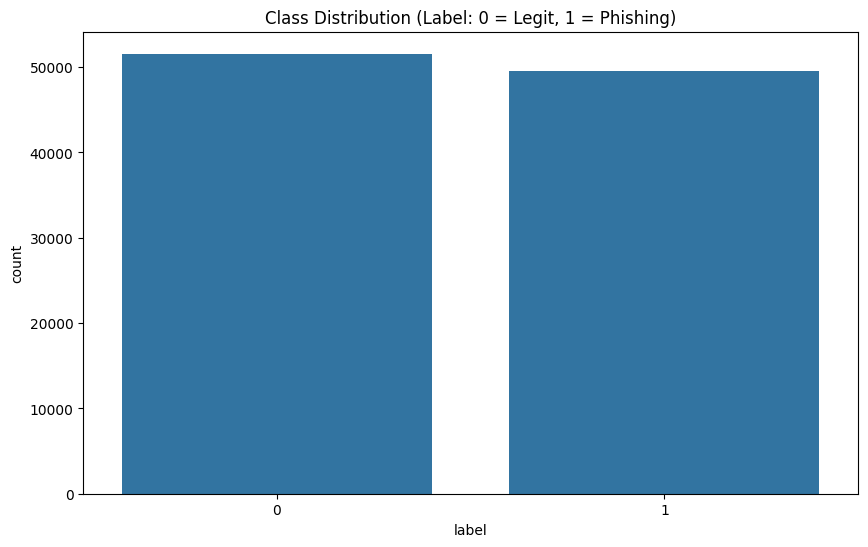

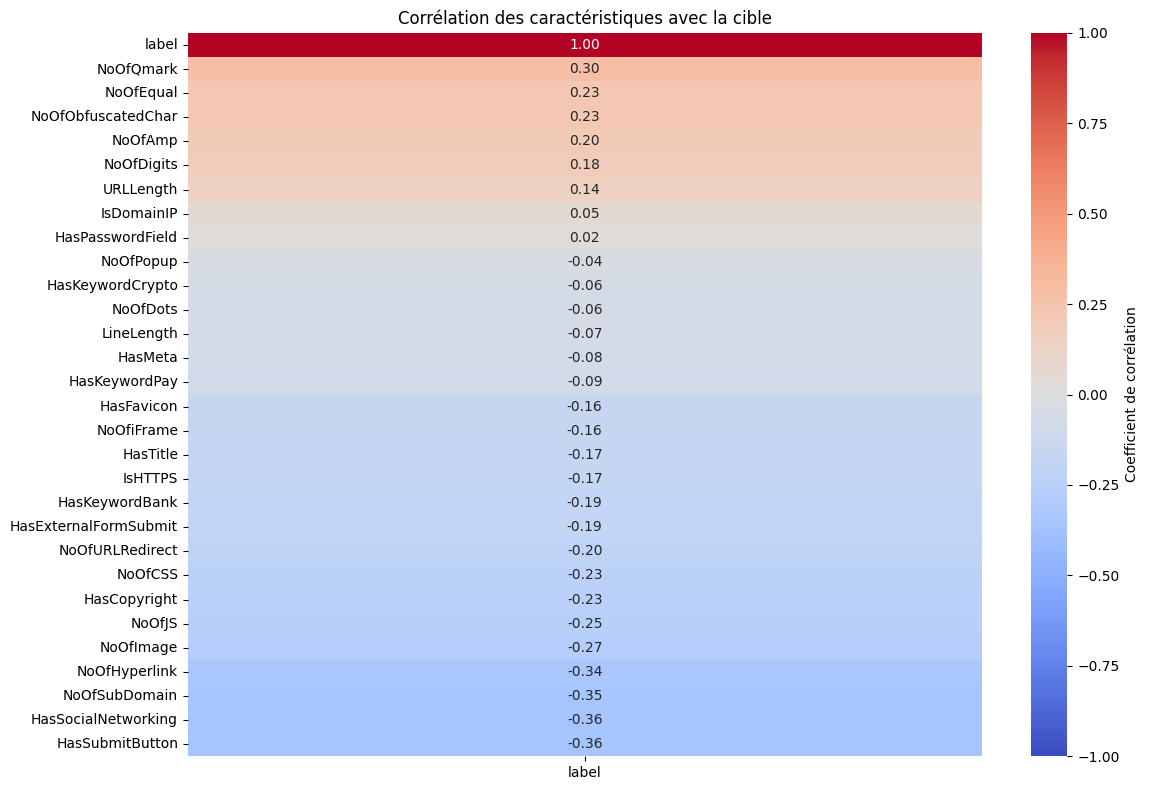

Contamination 0.005: Removed 504 points
Contamination 0.01: Removed 1011 points
Contamination 0.02: Removed 2022 points
Classes are balanced. SMOTE skipped.


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Number of positive: 38945, number of negative: 41096
[LightGBM] [Debug] Dataset::GetMultiBinFromSparseFeatures: sparse rate 0.861133
[LightGBM] [Debug] Dataset::GetMultiBinFromAllFeatures: sparse rate 0.564191
[LightGBM] [Debug] init for col-wise cost 0.017220 seconds, init for row-wise cost 0.024629 seconds
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.022174 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Debug] Using Sparse Multi-Val Bin
[LightGBM] [Info] Total Bins 1777
[LightGBM] [Info] Number of data points in the train set: 80041, number of used features: 29
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.486563 -> initscore=-0.053760
[LightGBM] [Info] Start training from score -0.053760
[LightGBM] [Debug] Trained a tree with leaves = 31 and depth = 12
[LightGBM] [Debug] Trained a tree with leaves = 31 and depth = 8
[LightGB

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.99      0.99     10275
           1       0.99      0.98      0.99      9736

    accuracy                           0.99     20011
   macro avg       0.99      0.99      0.99     20011
weighted avg       0.99      0.99      0.99     20011



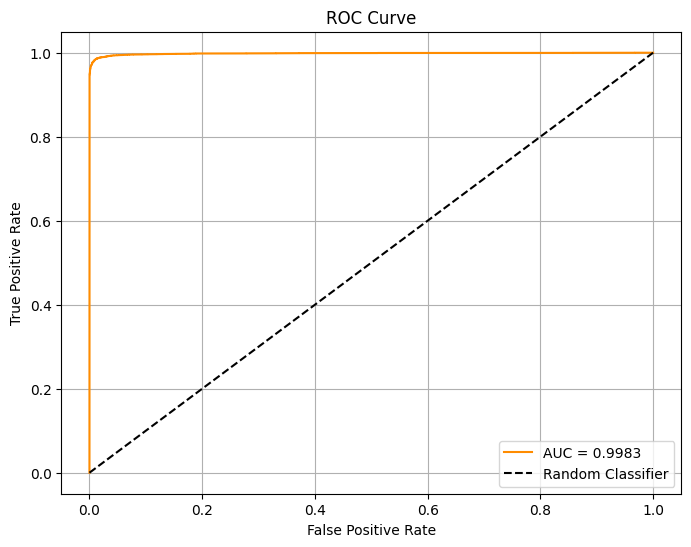

Validation Accuracy: 0.9868


In [8]:
# ---------------------------
# 0. Import necessary libraries
# ---------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc

from sklearn.ensemble import IsolationForest
from imblearn.over_sampling import SMOTE

# ---------------------------
# 1. Prepare data
# ---------------------------
# NOTE: Ensure you already have your DataFrame 'df' loaded
# Example: df = pd.read_csv("your_data.csv")

# Exploratory visualization
plt.figure(figsize=(10, 6))
sns.countplot(x='label', data=df)
plt.title('Class Distribution (Label: 0 = Legit, 1 = Phishing)')
plt.show()

plt.figure(figsize=(12, 8))
correlation = df.corr(numeric_only=True)
target_col = 'label'
sns.heatmap(correlation[[target_col]].sort_values(by=target_col, ascending=False),
            annot=True, cmap='coolwarm', vmin=-1, vmax=1,
            fmt='.2f', cbar_kws={'label': 'Coefficient de corrélation'})
plt.title('Corrélation des caractéristiques avec la cible')
plt.tight_layout()
plt.show()

# Select only numeric features
df = df.select_dtypes(include=[np.number, 'int64', 'float64'])

# Features / Target split
X = df.drop(columns=['label']).values
y = df['label'].astype(int).values

# ---------------------------
# 2. Feature normalization
# ---------------------------
scaler = StandardScaler()
X = scaler.fit_transform(X)

# ---------------------------
# 3. Anomaly detection with IsolationForest
# ---------------------------
for contamination in [0.005, 0.01, 0.02]:
    iso = IsolationForest(contamination=contamination, random_state=42)
    pred_anomalies = iso.fit_predict(X)
    mask = pred_anomalies != -1
    removed_points = len(X) - np.sum(mask)
    print(f"Contamination {contamination}: Removed {removed_points} points")

# Final chosen contamination level
chosen_contamination = 0.01
iso = IsolationForest(contamination=chosen_contamination, random_state=42)
pred_anomalies = iso.fit_predict(X)
mask = pred_anomalies != -1
X = X[mask]
y = y[mask]

# ---------------------------
# 4. Class balancing with SMOTE
# ---------------------------
if np.bincount(y).min() < np.bincount(y).max() * 0.5:
    smote = SMOTE(random_state=42)
    X, y = smote.fit_resample(X, y)
    print("Class distribution after SMOTE:", np.bincount(y))
else:
    print("Classes are balanced. SMOTE skipped.")

# ---------------------------
# 5. Train/test split
# ---------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

# ---------------------------
# 6. LightGBM model training
# ---------------------------
lgb_model = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=-1,
    num_leaves=31,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

lgb_model.fit(X_train, y_train)

# ---------------------------
# 7. Evaluation
# ---------------------------
# Predictions
y_pred = lgb_model.predict(X_test)
y_pred_proba = lgb_model.predict_proba(X_test)[:, 1]

# Classification report
print("Classification Report:\n", classification_report(y_test, y_pred))

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.4f}', color='darkorange')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.grid()
plt.show()

# Accuracy score
accuracy = (y_pred == y_test).mean()
print(f"Validation Accuracy: {accuracy:.4f}")
